# JS09 - Tugas Lab 1: Perbandingan Performa ANNOY, FAISS, dan HNSW

Lakukan percobaan pada **metric distance yang berbeda** (*Euclidean* dan *Angular/Cosine*), **1000 vs 1.000.000 data**, serta **2D vs 5D data** untuk algoritma:

1. ANNOY
2. FAISS
3. HNSW

Performansi dicatat dalam bentuk tabel (waktu *build index*, waktu *query*, dan *recall@10* terhadap hasil exact NN).

## Langkah 0 - Import Library

In [1]:
import numpy as np
import pandas as pd
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
import matplotlib.pyplot as plt

## Langkah 1 - Fungsi Benchmark

Setiap algoritma diukur tiga hal: **waktu build index**, **waktu query rata-rata** (dari 100 query), dan **recall@10** yaitu rasio tetangga yang ditemukan benar dibandingkan hasil exact NN (*brute force*).

Pemetaan metric distance untuk tiap algoritma:

- **Euclidean**: Annoy `'euclidean'`, FAISS `METRIC_L2`, HNSW `space='l2'`
- **Angular/Cosine**: Annoy `'angular'`, FAISS `METRIC_INNER_PRODUCT` pada vektor ternormalisasi (ekuivalen dengan cosine), HNSW `space='cosine'`

In [2]:
N_QUERIES = 100
K = 10

# -------------------------------
# Ground truth dengan brute force
# -------------------------------
def exact_topk(X, queries, metric, k=K):
    """Exact NN menggunakan FAISS IndexFlat (brute force)."""
    if metric == 'euclidean':
        index = faiss.IndexFlatL2(X.shape[1])
        xb = X.copy()
        xq = queries.copy()
    else:  # cosine -> inner product pada vektor ternormalisasi
        index = faiss.IndexFlatIP(X.shape[1])
        xb = X.copy()
        xq = queries.copy()
        faiss.normalize_L2(xb)
        faiss.normalize_L2(xq)
    index.add(xb)
    _, I = index.search(xq, k)
    return I

# -------------------------------
# Benchmark ANNOY
# -------------------------------
def benchmark_annoy(X, queries, metric, n_trees=10, k=K):
    f = X.shape[1]
    index = AnnoyIndex(f, 'euclidean' if metric == 'euclidean' else 'angular')

    start = time.time()
    for i, v in enumerate(X):
        index.add_item(i, v)
    index.build(n_trees)
    build_time = time.time() - start

    start = time.time()
    I = [index.get_nns_by_vector(q, k) for q in queries]
    query_time = (time.time() - start) * 1000 / len(queries)  # ms/query
    return build_time, query_time, np.array(I)

# -------------------------------
# Benchmark FAISS (IndexFlat)
# -------------------------------
def benchmark_faiss(X, queries, metric, k=K):
    d = X.shape[1]
    if metric == 'euclidean':
        index = faiss.IndexFlatL2(d)
        xb, xq = X.copy(), queries.copy()
    else:
        index = faiss.IndexFlatIP(d)
        xb, xq = X.copy(), queries.copy()
        faiss.normalize_L2(xb)
        faiss.normalize_L2(xq)

    start = time.time()
    index.add(xb)
    build_time = time.time() - start

    start = time.time()
    _, I = index.search(xq, k)
    query_time = (time.time() - start) * 1000 / len(xq)  # ms/query
    return build_time, query_time, I

# -------------------------------
# Benchmark HNSW (hnswlib)
# -------------------------------
def benchmark_hnsw(X, queries, metric, ef_construction=200, M=16, k=K):
    d = X.shape[1]
    space = 'l2' if metric == 'euclidean' else 'cosine'
    p = hnswlib.Index(space=space, dim=d)

    start = time.time()
    p.init_index(max_elements=X.shape[0], ef_construction=ef_construction, M=M)
    p.add_items(X)
    build_time = time.time() - start

    p.set_ef(50)  # tradeoff speed vs accuracy

    start = time.time()
    I, _ = p.knn_query(queries, k=k)
    query_time = (time.time() - start) * 1000 / len(queries)  # ms/query
    return build_time, query_time, I

# -------------------------------
# Recall@k terhadap exact NN
# -------------------------------
def recall_at_k(I_pred, I_gt, k=K):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)

## Langkah 2 - Menjalankan Eksperimen



In [3]:
np.random.seed(42)

configs = [
    (1_000, 2),
    (1_000_000, 5),
]
metrics = ['euclidean', 'cosine']

rows = []
for n_data, dim in configs:
    X = np.random.random((n_data, dim)).astype(np.float32)
    queries = np.random.random((N_QUERIES, dim)).astype(np.float32)

    for metric in metrics:
        gt = exact_topk(X, queries, metric)

        # Annoy
        build, qt, I = benchmark_annoy(X, queries, metric)
        rows.append({'Jumlah Data': n_data, 'Dimensi': dim, 'Metric': metric,
                     'Algoritma': 'ANNOY', 'Build Time (s)': build,
                     'Query Time (ms/query)': qt, 'Recall@10': recall_at_k(I, gt)})

        # FAISS
        build, qt, I = benchmark_faiss(X, queries, metric)
        rows.append({'Jumlah Data': n_data, 'Dimensi': dim, 'Metric': metric,
                     'Algoritma': 'FAISS', 'Build Time (s)': build,
                     'Query Time (ms/query)': qt, 'Recall@10': recall_at_k(I, gt)})

        # HNSW
        build, qt, I = benchmark_hnsw(X, queries, metric)
        rows.append({'Jumlah Data': n_data, 'Dimensi': dim, 'Metric': metric,
                     'Algoritma': 'HNSW', 'Build Time (s)': build,
                     'Query Time (ms/query)': qt, 'Recall@10': recall_at_k(I, gt)})

        print(f'Selesai: {n_data} data / {dim}D / {metric}')

hasil = pd.DataFrame(rows)
hasil.round(4)

Selesai: 1000 data / 2D / euclidean
Selesai: 1000 data / 2D / cosine


Selesai: 1000000 data / 5D / euclidean


Selesai: 1000000 data / 5D / cosine


,Jumlah Data,Dimensi,Metric,Algoritma,Build Time (s),Query Time (ms/query),Recall@10
0,1000,2,euclidean,ANNOY,0.0062,0.0235,0.993
1,1000,2,euclidean,FAISS,0.0000,0.0021,1.000
2,1000,2,euclidean,HNSW,0.0113,0.0098,1.000
3,1000,2,cosine,ANNOY,0.0083,0.0150,0.995
4,1000,2,cosine,FAISS,0.0000,0.0016,1.000
5,1000,2,cosine,HNSW,0.0092,0.0088,0.999
6,1000000,5,euclidean,ANNOY,5.6207,0.0409,0.948
7,1000000,5,euclidean,FAISS,0.0059,0.9901,1.000
8,1000000,5,euclidean,HNSW,38.3757,0.0254,1.000
9,1000000,5,cosine,ANNOY,6.5446,0.0412,0.981


### Analisis Hasil Eksperimen

1. **Build time** — FAISS `IndexFlat` tercepat karena hanya menambahkan data tanpa membangun struktur indeks. ANNOY menengah (±6 s untuk 1 juta data dengan 10 tree), sedangkan HNSW paling mahal (32–38 s) karena harus membangun graph multi-layer dengan `ef_construction=200`.
2. **Query time** — pada data kecil (1000/2D) ketiganya sama-sama cepat (<0.03 ms). Perbedaan drastis muncul pada 1 juta data: FAISS Flat melambat ~470× menjadi ±0.93–0.99 ms/query karena harus memindai seluruh data (*brute force*), sementara ANNOY (±0.04 ms) dan HNSW (±0.03 ms) tetap cepat berkat struktur indeksnya — speedup ±24–39× terhadap exact search.
3. **Recall@10** — HNSW nyaris sempurna (0.999–1.000) meskipun *approximate*. ANNOY paling rendah (0.948–0.995) namun masih sangat baik; recall-nya dapat dinaikkan dengan menambah jumlah tree atau `search_k` dengan konsekuensi query yang lebih lambat.
4. **Metric distance** (Euclidean vs Angular/Cosine) tidak mengubah pola kesimpulan; hanya memengaruhi nilai recall ANNOY sedikit.

**Kesimpulan:** terdapat *trade-off* antara biaya build, kecepatan query, dan akurasi. HNSW memberikan query tercepat dengan recall nyaris sempurna tetapi build paling lama; ANNOY paling seimbang antara build cepat dan akurasi; FAISS Flat cocok ketika data dapat ditampung di memori dan akurasi sempurna diutamakan.

## Langkah 3 - Tabel Performansi (Format Modul)

In [4]:
# Format tabel sesuai modul: satu baris per kombinasi (jumlah data/dimensi, metric)
def fmt(row):
    return f"build {row['Build Time (s)']:.3f} s; query {row['Query Time (ms/query)']:.4f} ms; recall {row['Recall@10']:.3f}"

tabel = {}
for (n_data, dim, metric), g in hasil.groupby(['Jumlah Data', 'Dimensi', 'Metric'], sort=False):
    label = f'{n_data:,}/{dim}D ({metric})'
    tabel[label] = {a: fmt(g[g['Algoritma'] == a].iloc[0]) for a in ['ANNOY', 'FAISS', 'HNSW']}

tabel_modul = pd.DataFrame(tabel).T
tabel_modul.index.name = 'Jumlah Data/Dimensi'
tabel_modul

,ANNOY,FAISS,HNSW
Jumlah Data/Dimensi,,,
"1,000/2D (euclidean)",build 0.006 s; query 0.0235 ms; recall 0.993,build 0.000 s; query 0.0021 ms; recall 1.000,build 0.011 s; query 0.0098 ms; recall 1.000
"1,000/2D (cosine)",build 0.008 s; query 0.0150 ms; recall 0.995,build 0.000 s; query 0.0016 ms; recall 1.000,build 0.009 s; query 0.0088 ms; recall 0.999
"1,000,000/5D (euclidean)",build 5.621 s; query 0.0409 ms; recall 0.948,build 0.006 s; query 0.9901 ms; recall 1.000,build 38.376 s; query 0.0254 ms; recall 1.000
"1,000,000/5D (cosine)",build 6.545 s; query 0.0412 ms; recall 0.981,build 0.006 s; query 0.9267 ms; recall 1.000,build 31.730 s; query 0.0387 ms; recall 1.000


## Langkah 4 - Visualisasi Perbandingan

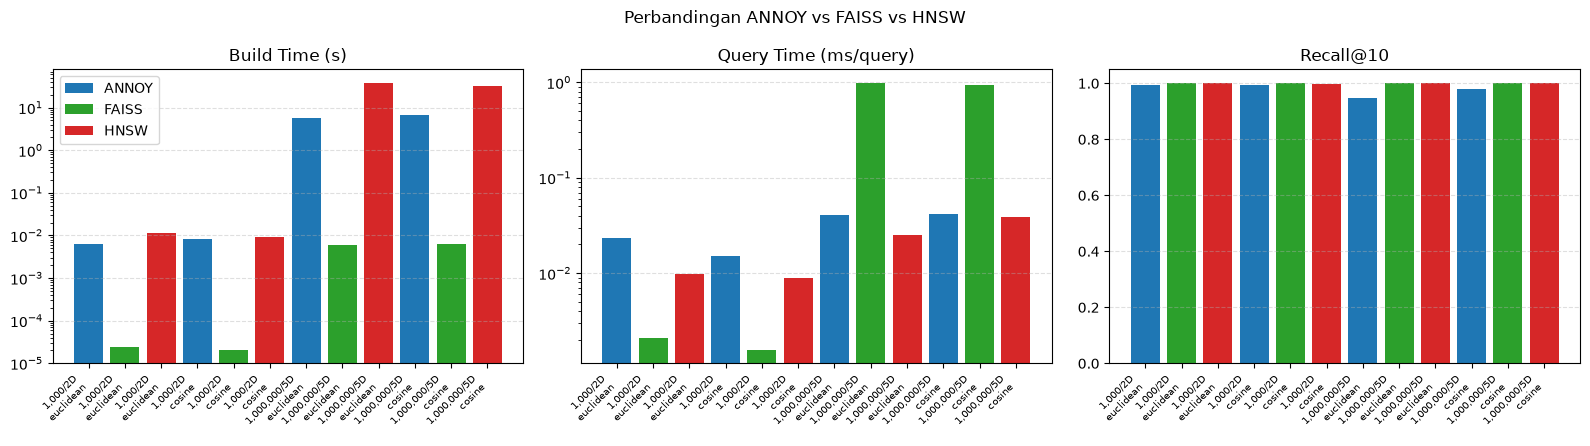

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

labels = [f"{n:,}/{d}D\n{m}" for n, d, m in
          zip(hasil['Jumlah Data'], hasil['Dimensi'], hasil['Metric'])]
x = np.arange(len(hasil))
colors = {'ANNOY': 'tab:blue', 'FAISS': 'tab:green', 'HNSW': 'tab:red'}

for ax, col, title, log in [
    (axes[0], 'Build Time (s)', 'Build Time (s)', True),
    (axes[1], 'Query Time (ms/query)', 'Query Time (ms/query)', True),
    (axes[2], 'Recall@10', 'Recall@10', False),
]:
    for algo in ['ANNOY', 'FAISS', 'HNSW']:
        mask = hasil['Algoritma'] == algo
        ax.bar(x[mask], hasil.loc[mask, col], label=algo, color=colors[algo])
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=7)
    ax.set_title(title)
    if log:
        ax.set_yscale('log')
    ax.grid(True, axis='y', ls='--', alpha=0.4)

axes[0].legend()
plt.suptitle('Perbandingan ANNOY vs FAISS vs HNSW')
plt.tight_layout()
plt.show()